$$
\begin{array}{c}
{\Huge \text{CAUSAL INFERENCE LAB 10}}\\
{\Large \textbf{Abhishek Bakshi}} \\
{\large \textit{Center for Data Science, New York University}} \\\\
{\Large \text{Office Hours: Wednesdays, 12:30 - 1:30 pm}} \\
{\Large \textit{Room 242, 60 5th Ave, 2nd floor}} \\\\
\text{Materials prepared by: Abhishek Bakshi, Xiang Gao}
\end{array}
$$

---

<h1 style="font-size: 42px;">Instrumental Variables and Regression Discontinuity</h1>

---

<h1 style="font-size: 30px;">Today's Goals:</h1>

<ol style="font-size: 20px; line-height: 1.6;">
  <li>The Wald estimator and two-stage least squares</li>
  <li>Instruments with controls</li>
  <li>Weak instruments</li>
  <li>Regression discontinuity: the cutoff rule</li>
  <li>Bandwidths</li>
  <li>Checking the design</li>
</ol>

---

<style>
body,
.jp-RenderedHTMLCommon,
.jp-RenderedMarkdown,
.markdown-body,
.vscode-body {
  font-family: Arial, Helvetica, sans-serif !important;
}
p, li, blockquote, td, th {
  font-size: 20px !important;
  line-height: 1.6 !important;
}
h1 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 42px !important;
  line-height: 1.25 !important;
  margin-top: 0.6em !important;
}
h2 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 30px !important;
  line-height: 1.3 !important;
  margin-top: 0.7em !important;
  border-bottom: 2px solid #469110;
  padding-bottom: 0.15em;
}
h3 {
  font-family: Arial, Helvetica, sans-serif !important;
  font-size: 25px !important;
  line-height: 1.35 !important;
  margin-top: 0.7em !important;
}
table { font-size: 19px !important; line-height: 1.45 !important; }
code, pre { font-size: 17px !important; }
blockquote { border-left: 5px solid #660033 !important; padding: 0.3em 0.8em !important; }
.MathJax, mjx-container { font-size: 115% !important; }
</style>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

pd.set_option("display.precision", 3)
plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 19, "axes.labelsize": 16,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E6E3E4", "grid.linewidth": 0.8,
    "legend.frameon": False,
    "text.color": "#1F1418", "axes.titlecolor": "#1F1418", "axes.edgecolor": "#C7C4C5",
    "axes.labelcolor": "#625B5D", "xtick.labelcolor": "#625B5D", "ytick.labelcolor": "#625B5D",
    "xtick.color": "#C7C4C5", "ytick.color": "#C7C4C5",
    "figure.constrained_layout.use": True,
})
SEED = 107
# Every cell that draws random numbers makes its own generator from SEED,
# so re-running a cell gives the same numbers.


def robust(formula, data):
    """OLS with robust (HC0) standard errors."""
    return smf.ols(formula, data=data).fit(cov_type="HC0")


print("Ready: instrumental variables and regression discontinuity.")

Ready: instrumental variables and regression discontinuity.


## 1. From the judge to the effect of prison

---

We want the effect of prison on re-offending:

- $Y=1$ if the person commits another crime within five years, 0 if not
- $S=1$ if they go to prison, 0 if not
- $Z=1$ if the mean judge hears the case, 0 if the nice judge does

The town has two judges who work different days, and a case goes to whichever judge sits on the day it comes to trial. Murderers go to prison with either judge, litterers with neither, and shoplifters only with the mean judge. Prison lowers re-offending by 30 points for murderers and 10 points for shoplifters, and makes no difference for litterers.

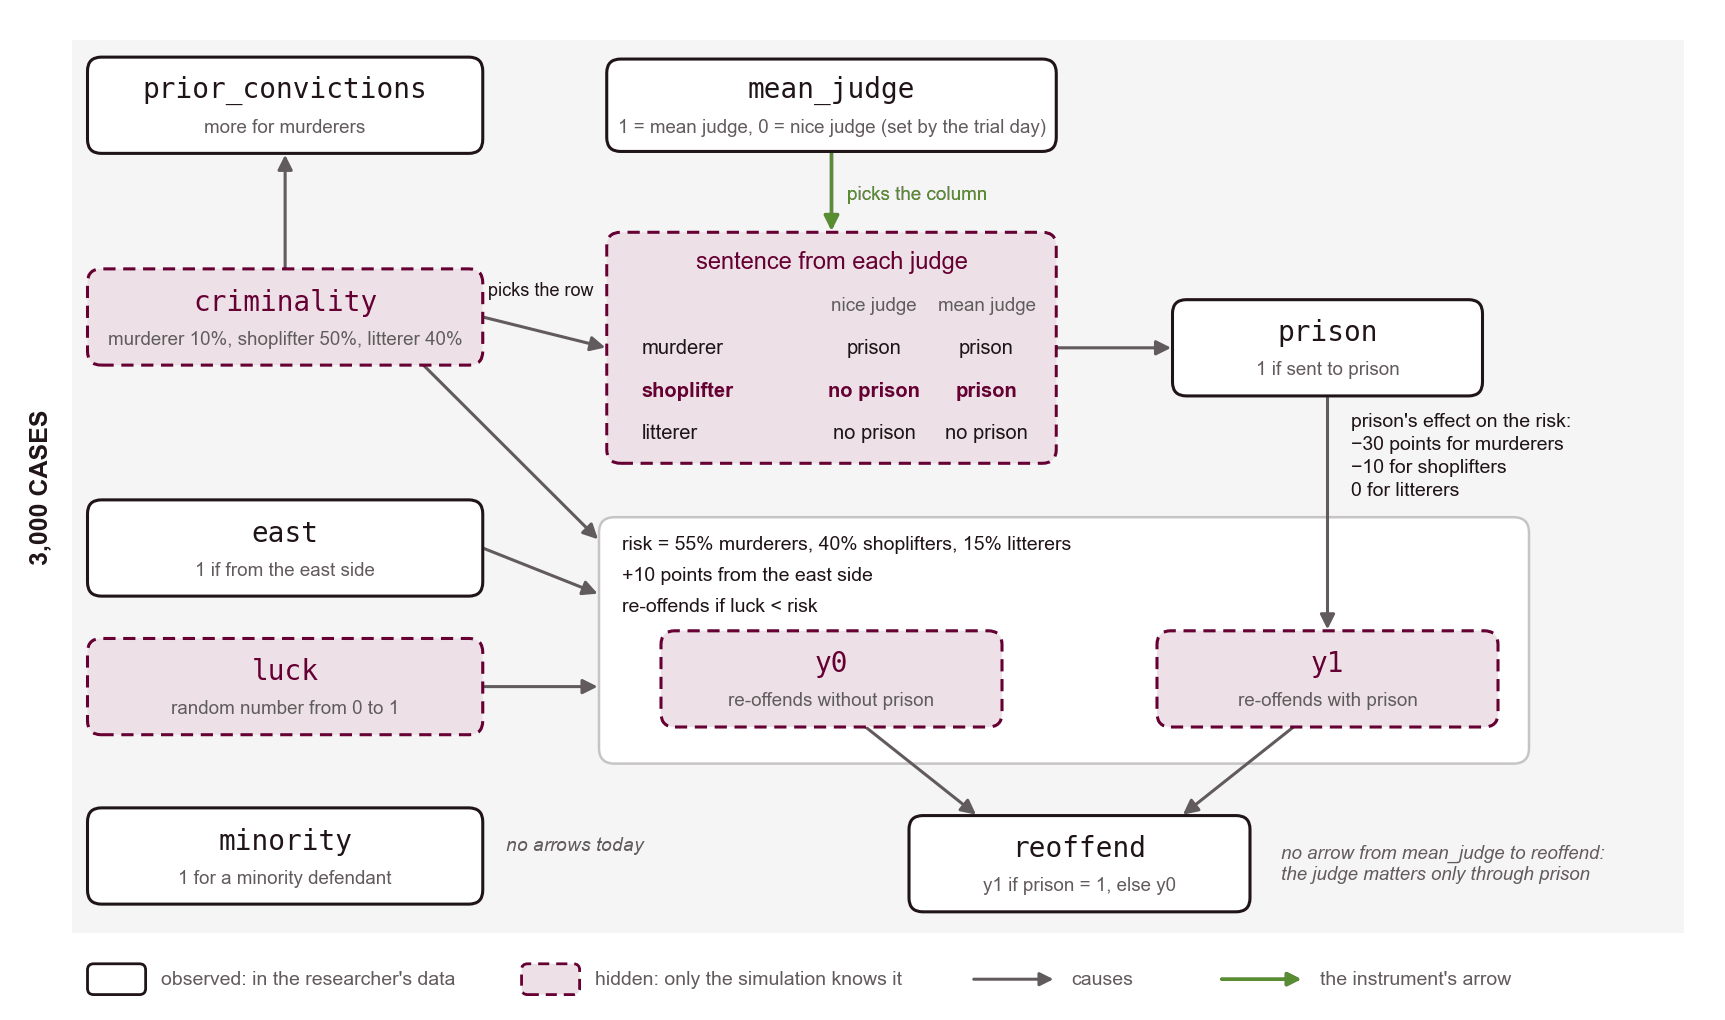

IV identifies the local average treatment effect (LATE), the effect of prison for the people whose sentence depends on the judge, under three assumptions:

- **Instrument exogeneity:** $U,V\perp Z$
- **Instrument relevance:** $S(Z=1,V)\neq S(Z=0,V)$ sometimes
- **Monotonicity:** $S(Z=1,V)\geq S(Z=0,V)$ always

$Z$ does not appear in $Y(S,U)$: the judge has no direct effect on re-offending.

In [2]:
def make_cases(n, rng, mean_judge_east=0.5, mean_judge_west=0.5, fines=False, biased_nice_judge=False):
    """Criminal cases in a town with two judges. The last four arguments change how the court works."""
    # Background
    criminality = rng.choice(["murderer", "shoplifter", "litterer"], size=n, p=[0.10, 0.50, 0.40])   # UNOBSERVED
    murderer, shoplifter = criminality == "murderer", criminality == "shoplifter"
    east = rng.binomial(1, 0.5, n)                       # 1 if from the east side
    minority = rng.binomial(1, 0.4, n)
    prior_convictions = rng.poisson(np.select([murderer, shoplifter], [2.0, 1.0], 0.5))

    # Z: which judge sits on the day of trial (1 = mean judge, 0 = nice judge)
    day = rng.uniform(0, 1, n)
    mean_judge = (day < np.where(east == 1, mean_judge_east, mean_judge_west)).astype(int)

    # The sentence each judge would give: S(Z=0, V) and S(Z=1, V)
    prison_by_nice_judge = murderer.astype(int)                    # UNOBSERVED
    prison_by_mean_judge = (murderer | shoplifter).astype(int)     # UNOBSERVED
    if biased_nice_judge:   # the nice judge jails minority shoplifters; the mean judge doesn't
        minority_shoplifter = shoplifter & (minority == 1)
        prison_by_nice_judge = np.where(minority_shoplifter, 1, prison_by_nice_judge)
        prison_by_mean_judge = np.where(minority_shoplifter, 0, prison_by_mean_judge)
    prison = np.where(mean_judge == 1, prison_by_mean_judge, prison_by_nice_judge)

    # Re-offending within five years, without prison (y0) and with prison (y1)
    risk = np.select([murderer, shoplifter], [0.55, 0.40], 0.15) + 0.10 * east
    prison_effect = np.select([murderer, shoplifter], [-0.30, -0.10], 0.0)
    luck = rng.uniform(0, 1, n)                                    # UNOBSERVED
    y0 = (luck < risk).astype(int)                                 # UNOBSERVED
    y1 = (luck < risk + prison_effect).astype(int)                 # UNOBSERVED
    reoffend = np.where(prison == 1, y1, y0)                       # only one outcome is ever seen
    if fines:   # the mean judge also fines everyone not sent to prison (+10 points)
        fined = (mean_judge == 1) & (prison == 0)
        reoffend = np.where(fined, (luck < risk + 0.10).astype(int), reoffend)

    return pd.DataFrame({
        "east": east, "minority": minority, "prior_convictions": prior_convictions,
        "mean_judge": mean_judge, "prison": prison, "reoffend": reoffend,
        # columns no researcher would ever see:
        "criminality": criminality, "prison_by_nice_judge": prison_by_nice_judge,
        "prison_by_mean_judge": prison_by_mean_judge, "y0": y0, "y1": y1,
    })


HIDDEN = ["criminality", "prison_by_nice_judge", "prison_by_mean_judge", "y0", "y1"]

cases = make_cases(3_000, np.random.default_rng(SEED + 390))
observed = cases.drop(columns=HIDDEN)
print(f"{len(cases):,} cases; the mean judge heard {cases.mean_judge.sum():,} of them")

3,000 cases; the mean judge heard 1,515 of them


### The Wald estimator

Start with a constant effect: $Y=\alpha_0+\alpha_1S+U$ with $\mathbb E[U]=0$. We can't say $\mathbb E[SU]=0$, but exogeneity gives $\mathbb E[ZU]=0$, and the same steps as for regression give

$$
\alpha_1^{IV}=\frac{\mathrm{Cov}(Z,Y)}{\mathrm{Cov}(Z,S)}.
$$

For a binary $Z$, dividing the top and the bottom by $\mathrm{Var}(Z)$ turns each covariance into a difference in means:

$$
\alpha_1^{IV}=\frac{\mathbb E[Y\mid Z=1]-\mathbb E[Y\mid Z=0]}{\mathbb E[S\mid Z=1]-\mathbb E[S\mid Z=0]}.
$$

When the effect differs from person to person, the three assumptions still give a clean answer. The numerator is $\mathbb E[Y(S=1,U)-Y(S=0,U)\mid\text{Complier}]\,P(\text{Complier})$ and the denominator is $P(\text{Complier})$, so the ratio is the LATE.

### Question 1

1. What would happen to the ratio if the mean judge sent exactly the same people to prison as the nice judge?
2. What would happen to the ratio if prison had no effect on anyone?
3. Prison lowers murderers' re-offending by 30 points. Does that effect enter the ratio anywhere?

In [3]:
mean_cases = observed[observed.mean_judge == 1]
nice_cases = observed[observed.mean_judge == 0]
prison_gap = mean_cases.prison.mean() - nice_cases.prison.mean()          # E[S|Z=1] - E[S|Z=0]
reoffend_gap = mean_cases.reoffend.mean() - nice_cases.reoffend.mean()    # E[Y|Z=1] - E[Y|Z=0]
print(f"Prison, mean judge minus nice judge: {100 * prison_gap:+.1f} points")
print(f"Re-offending, mean judge minus nice judge: {100 * reoffend_gap:+.1f} points")
wald = reoffend_gap / prison_gap
print(f"Wald estimate: {100 * reoffend_gap:.1f} / {100 * prison_gap:.1f} = {100 * wald:+.1f} points")

cov = observed[["mean_judge", "prison", "reoffend"]].cov()
cov_zy, cov_zs = cov.loc["mean_judge", "reoffend"], cov.loc["mean_judge", "prison"]
print(f"Cov(Z, Y) / Cov(Z, S) = {cov_zy:.4f} / {cov_zs:.4f} = {100 * cov_zy / cov_zs:+.1f} points")

complier = (cases.prison_by_nice_judge == 0) & (cases.prison_by_mean_judge == 1)    # hidden
true_late = (cases.y1 - cases.y0)[complier].mean()
print(f"True LATE (hidden): {100 * true_late:+.1f} points")

Prison, mean judge minus nice judge: +49.1 points
Re-offending, mean judge minus nice judge: -5.8 points
Wald estimate: -5.8 / 49.1 = -11.7 points
Cov(Z, Y) / Cov(Z, S) = -0.0144 / 0.1228 = -11.7 points
True LATE (hidden): -10.5 points


### Two-stage least squares

In practice a package does this. **Two-stage least squares** (2SLS) first predicts $S$ from $Z$ (the first stage), then regresses $Y$ on that prediction, so it only uses the part of $S$ that comes from $Z$. In `linearmodels`, `IV2SLS.from_formula("Y ~ 1 + [S ~ Z]", data)` does both stages. The brackets read "the variation in $S$ that comes from $Z$".

We'll set it next to the plain regression of $Y$ on $S$, which uses all of the variation in $S$. Its slope is $\mathrm{Cov}(S,Y)/\mathrm{Var}(S)$.

### Question 2: predict before running

1. Will the plain regression's slope be above or below the LATE? Could it even have the wrong sign? Why?
2. Which of the two estimates will have the wider confidence interval? Why?

In [4]:
plain = robust("reoffend ~ prison", observed)
low, high = plain.conf_int().loc["prison"]
print(f"Regression of Y on S: {100 * plain.params['prison']:+.1f} points (robust SE {100 * plain.bse['prison']:.1f}; "
      f"95% CI {100 * low:+.1f} to {100 * high:+.1f})")

iv = IV2SLS.from_formula("reoffend ~ 1 + [prison ~ mean_judge]", observed).fit(cov_type="robust")
low, high = iv.conf_int().loc["prison"]
print(f"2SLS: {100 * iv.params['prison']:+.1f} points (robust SE {100 * iv.std_errors['prison']:.1f}; "
      f"95% CI {100 * low:+.1f} to {100 * high:+.1f})")
print(f"True LATE (hidden): {100 * true_late:+.1f} points")

Regression of Y on S: +4.0 points (robust SE 1.8; 95% CI +0.5 to +7.5)
2SLS: -11.7 points (robust SE 3.5; 95% CI -18.5 to -4.9)
True LATE (hidden): -10.5 points


## 2. Instruments with controls

---

Suppose the mean judge sits in the east-side courthouse and hears 80% of east-side cases but only 20% of west-side cases. People from the east side, where there are fewer jobs, re-offend more whatever their sentence, so $Z\not\perp U$. Within each side, though, the trial day still decides the judge:

$$
Z\perp U\mid \text{east}.
$$

IV with a control adds `east` to both stages: `Y ~ 1 + east + [S ~ Z]`. The estimate is then no longer a single LATE. It becomes a weighted average of the two sides' LATEs,

$$
\alpha_1^{IV,\text{cont}}=\sum_{\text{side}}w_{\text{side}}\,\text{LATE}(\text{side}),\qquad
w_{\text{side}}\propto P(\text{side})\,\mathrm{Cov}(Z,S\mid\text{side}),
$$

with the weights scaled to add up to 1. For a binary $Z$,

$$
\mathrm{Cov}(Z,S\mid\text{side})=p\,(1-p)\times\big(\mathbb E[S\mid Z=1,\text{side}]-\mathbb E[S\mid Z=0,\text{side}]\big),
$$

where $p$ is the share of the side's cases that the mean judge hears, and the bracket is the side's first stage. So a side gets more weight when it has more cases, when the judge changes more of its sentences, and when its $p$ is closer to 50%.

### Question 3: predict before running

1. Without the control, will the estimate be too high or too low? Why?
2. The two sides have about the same number of cases and the same mix of crimes. With the control, which side's LATE will get more weight? Use the formula.

In [5]:
by_side = make_cases(3_000, np.random.default_rng(SEED + 390), mean_judge_east=0.8, mean_judge_west=0.2)

rows = []
for label, formula, data in [
        ("No control", "reoffend ~ 1 + [prison ~ mean_judge]", by_side),
        ("Control for east", "reoffend ~ 1 + east + [prison ~ mean_judge]", by_side),
        ("East side only", "reoffend ~ 1 + [prison ~ mean_judge]", by_side[by_side.east == 1]),
        ("West side only", "reoffend ~ 1 + [prison ~ mean_judge]", by_side[by_side.east == 0])]:
    fit = IV2SLS.from_formula(formula, data).fit(cov_type="robust")
    low, high = fit.conf_int().loc["prison"]
    rows.append({"2SLS": label, "Cases": len(data), "Effect of prison (points)": 100 * fit.params["prison"],
                 "95% CI": f"{100 * low:+.1f} to {100 * high:+.1f}"})
display(pd.DataFrame(rows).style.format({"Effect of prison (points)": "{:+.1f}"}).hide(axis="index"))
print(f"True LATE (hidden): {100 * true_late:+.1f} points")

2SLS,Cases,Effect of prison (points),95% CI
No control,3000,+1.0,-5.6 to +7.5
Control for east,3000,-9.1,-17.0 to -1.2
East side only,1481,-8.1,-20.0 to +3.8
West side only,1519,-10.0,-20.5 to +0.5


True LATE (hidden): -10.5 points


### The weights

Now compute each side's weight from the formula, and check that the weighted average of the two sides' LATEs gives the estimate with the control.

In [6]:
rows = []
for side, name in [(1, "East"), (0, "West")]:
    part = by_side[by_side.east == side]
    p = part.mean_judge.mean()
    first_stage = part[part.mean_judge == 1].prison.mean() - part[part.mean_judge == 0].prison.mean()
    late = IV2SLS.from_formula("reoffend ~ 1 + [prison ~ mean_judge]", part).fit(cov_type="robust").params["prison"]
    rows.append({"Side": name, "Cases": len(part), "p": p, "p(1 - p)": p * (1 - p), "First stage": first_stage,
                 "Cov(Z, S | side)": p * (1 - p) * first_stage, "LATE (points)": 100 * late})
weights = pd.DataFrame(rows)
weights["Weight"] = weights["Cases"] * weights["Cov(Z, S | side)"]
weights["Weight"] /= weights["Weight"].sum()                 # scale the weights to add up to 1
display(weights.style.format({"Cases": "{:,}", "p": "{:.2f}", "p(1 - p)": "{:.3f}", "First stage": "{:.3f}",
                              "Cov(Z, S | side)": "{:.4f}", "LATE (points)": "{:+.1f}", "Weight": "{:.2f}"})
        .hide(axis="index"))

east_row, west_row = weights.iloc[0], weights.iloc[1]
average = (weights["Weight"] * weights["LATE (points)"]).sum()
control = IV2SLS.from_formula("reoffend ~ 1 + east + [prison ~ mean_judge]", by_side).fit(cov_type="robust")
print(f"Weighted average: {east_row['Weight']:.2f} × ({east_row['LATE (points)']:+.1f}) + "
      f"{west_row['Weight']:.2f} × ({west_row['LATE (points)']:+.1f}) = {average:+.1f} points")
print(f"2SLS with the control for east: {100 * control.params['prison']:+.1f} points")

Side,Cases,p,p(1 - p),First stage,"Cov(Z, S | side)",LATE (points),Weight
East,"1,481",0.80,0.162,0.512,0.0829,-8.1,0.49
West,"1,519",0.21,0.165,0.520,0.0856,-10.0,0.51


Weighted average: 0.49 × (-8.1) + 0.51 × (-10.0) = -9.1 points
2SLS with the control for east: -9.1 points


### Fines

The judges are back to working different days. Now the mean judge also fines everyone not sent to prison, and the fines push some of them back into crime (+10 points). Sentences don't change.

### Question 4: predict before running

1. Will the 2SLS estimate be too high or too low? Why?
2. Would adding `east`, or any other column, as a control fix it?

In [7]:
fined = make_cases(3_000, np.random.default_rng(SEED + 390), fines=True)

for label, formula in [("No control", "reoffend ~ 1 + [prison ~ mean_judge]"),
                       ("Control for east", "reoffend ~ 1 + east + [prison ~ mean_judge]")]:
    fit = IV2SLS.from_formula(formula, fined).fit(cov_type="robust")
    low, high = fit.conf_int().loc["prison"]
    print(f"{label}: {100 * fit.params['prison']:+.1f} points (95% CI {100 * low:+.1f} to {100 * high:+.1f})")
print(f"True LATE (hidden): {100 * true_late:+.1f} points")

No control: -3.5 points (95% CI -10.4 to +3.3)


Control for east: -3.6 points (95% CI -10.4 to +3.2)
True LATE (hidden): -10.5 points


## 3. Weak instruments

---

A new question: does having a third child change whether a mother works for pay? Mothers who want big families may differ in many ways from those who stop at two, so $S\not\perp U$. But many parents want at least one boy and one girl, so parents whose first two children are the same sex are more likely to try for a third. A child's sex is as good as random.

- $Y=1$ if the mother works for pay, 0 if not
- $S=1$ if she has a third child, 0 if she stops at two
- $Z=1$ if her first two children are both boys or both girls, 0 if one of each

In our simulated version, each child is a boy or a girl with equal chance. 37% of mothers would have a third child anyway, 6% only if the first two are the same sex, and 57% would stop at two. Which group a mother is in is hidden. Without a third child, 50%, 55% and 60% of these groups would work, and a third child lowers that by 9 points for everyone.

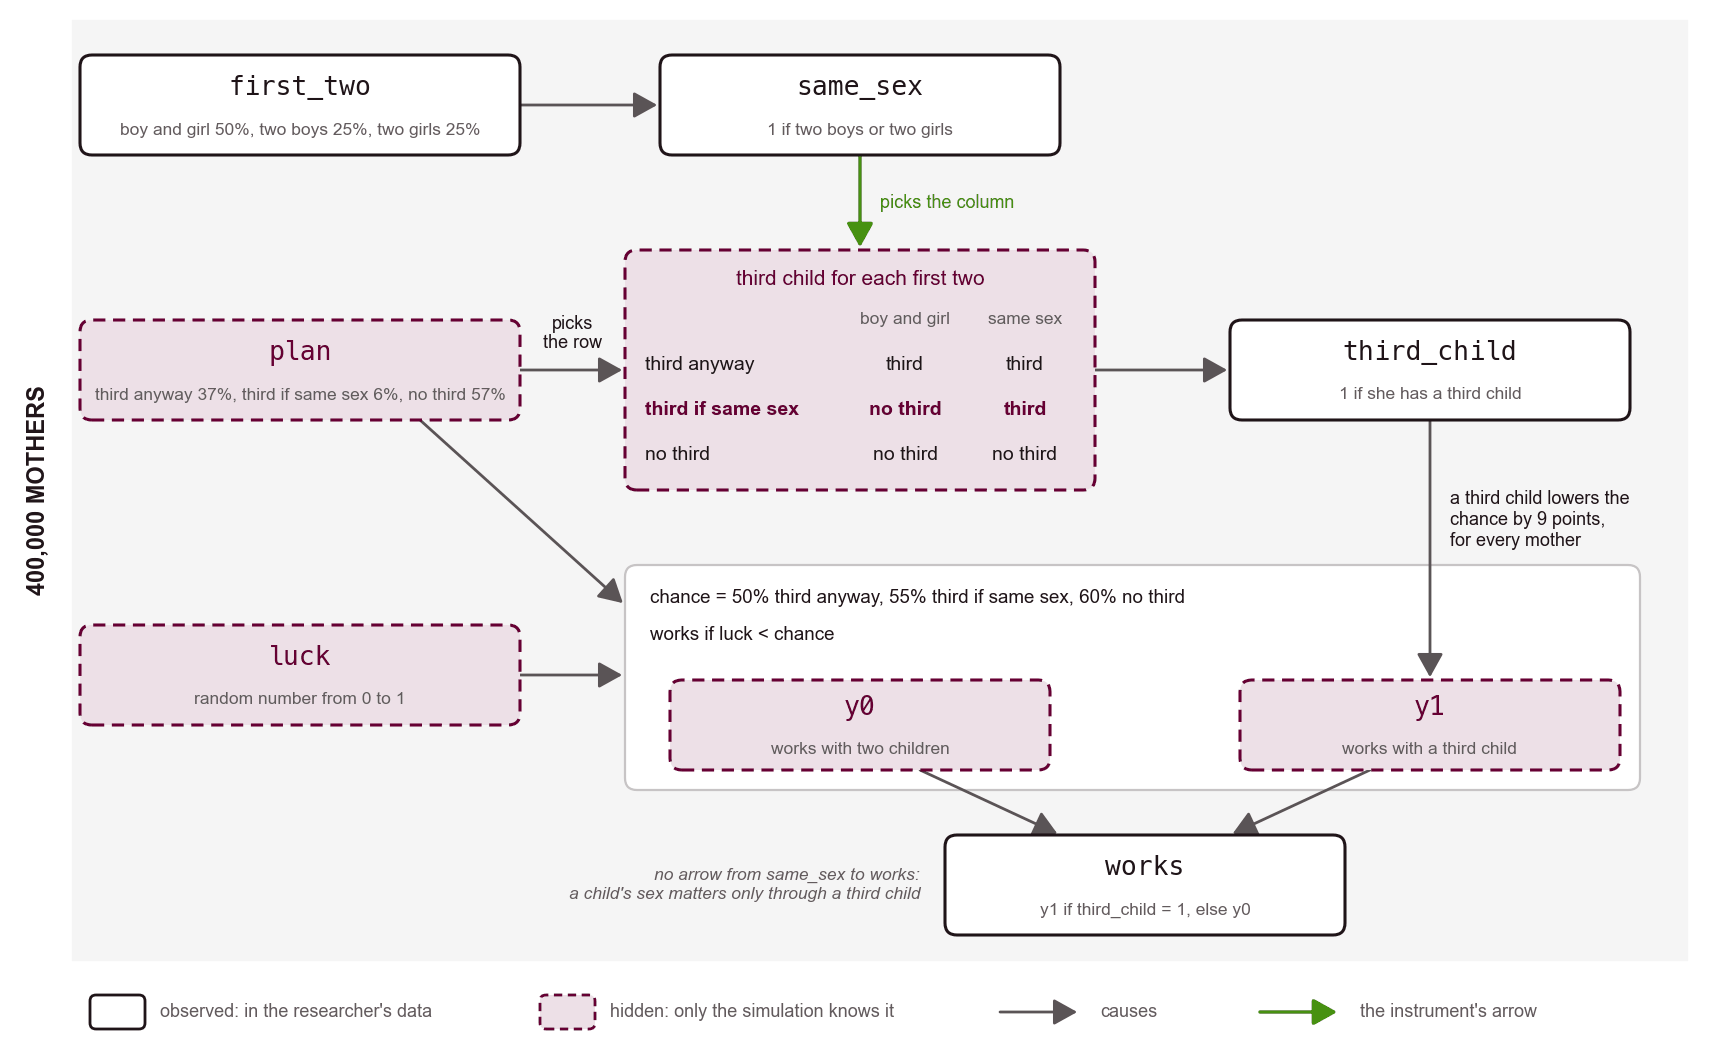

An instrument can be valid and still hard to learn from. If it moves $S$ only rarely, $\mathrm{Cov}(Z,S)\approx 0$, and dividing by it can blow the estimate up. So look at the first stage, $S=\beta_0+\beta_1Z$. A common rule of thumb calls the instrument weak if the first stage's $F$ statistic is below 10.

### Question 5: predict before running

We start with one study of 400,000 mothers, about the size of a census sample.

1. Suppose boys were harder to raise, so some parents with two boys would stop at two even though they'd have tried for a third after a boy and a girl. Which assumption would that break, and what would the third-child rates by `first_two` show?
2. The first stage is about 6 points. Roughly how big is its standard error with 400,000 mothers, and will $F$ pass 10? ($F$ is about $(\text{estimate}/\text{SE})^2$.)

In [8]:
def make_mothers(n, rng):
    """Mothers with at least two children. Does a third child change whether she works for pay?"""
    first_two = rng.choice(["boy and girl", "two boys", "two girls"], size=n, p=[0.50, 0.25, 0.25])
    same_sex = (first_two != "boy and girl").astype(int)                                   # Z
    plan = rng.choice(["third anyway", "third if same sex", "no third"], size=n, p=[0.37, 0.06, 0.57])  # UNOBSERVED
    third_child = ((plan == "third anyway") | ((plan == "third if same sex") & (same_sex == 1))).astype(int)  # S

    # Works for pay with two children (y0) and with a third (y1)
    chance = np.select([plan == "third anyway", plan == "third if same sex"], [0.50, 0.55], 0.60)
    luck = rng.uniform(0, 1, n)                                                            # UNOBSERVED
    y0 = (luck < chance).astype(int)                                                       # UNOBSERVED
    y1 = (luck < chance - 0.09).astype(int)                                                # UNOBSERVED
    works = np.where(third_child == 1, y1, y0)
    return pd.DataFrame({"first_two": first_two, "same_sex": same_sex,
                         "third_child": third_child, "works": works})


mothers = make_mothers(400_000, np.random.default_rng(SEED + 57))
display(mothers.groupby("first_two").third_child.mean().to_frame("Had a third child").style.format("{:.3f}"))

raw = robust("works ~ third_child", mothers)
first_stage = robust("third_child ~ same_sex", mothers)
reduced_form = robust("works ~ same_sex", mothers)
iv = IV2SLS.from_formula("works ~ 1 + [third_child ~ same_sex]", mothers).fit(cov_type="robust")
low, high = iv.conf_int().loc["third_child"]
print(f"Raw: mothers with a third child work {100 * raw.params['third_child']:+.1f} points")
print(f"First stage: same sex raises the chance of a third child by "
      f"{100 * first_stage.params['same_sex']:.1f} points (SE {100 * first_stage.bse['same_sex']:.2f}, "
      f"F = {first_stage.fvalue:,.0f})")
print(f"Reduced form: same sex changes working by {100 * reduced_form.params['same_sex']:+.2f} points")
print(f"2SLS: {100 * iv.params['third_child']:+.1f} points (95% CI {100 * low:+.1f} to {100 * high:+.1f})")

,Had a third child
first_two,
boy and girl,0.370
two boys,0.429
two girls,0.430


Raw: mothers with a third child work -18.4 points
First stage: same sex raises the chance of a third child by 6.0 points (SE 0.15, F = 1,500)
Reduced form: same sex changes working by -0.53 points
2SLS: -8.8 points (95% CI -13.9 to -3.7)


### Question 6: predict before running

Now we repeat the study many times, with the same instrument and the same truth: 100 studies of 400,000 mothers and 500 studies of 2,000 mothers.

1. With 2,000 mothers instead of 400,000, what happens to the first stage's standard error, and to $F$?
2. What will the estimates from the small studies look like next to those from the big studies?

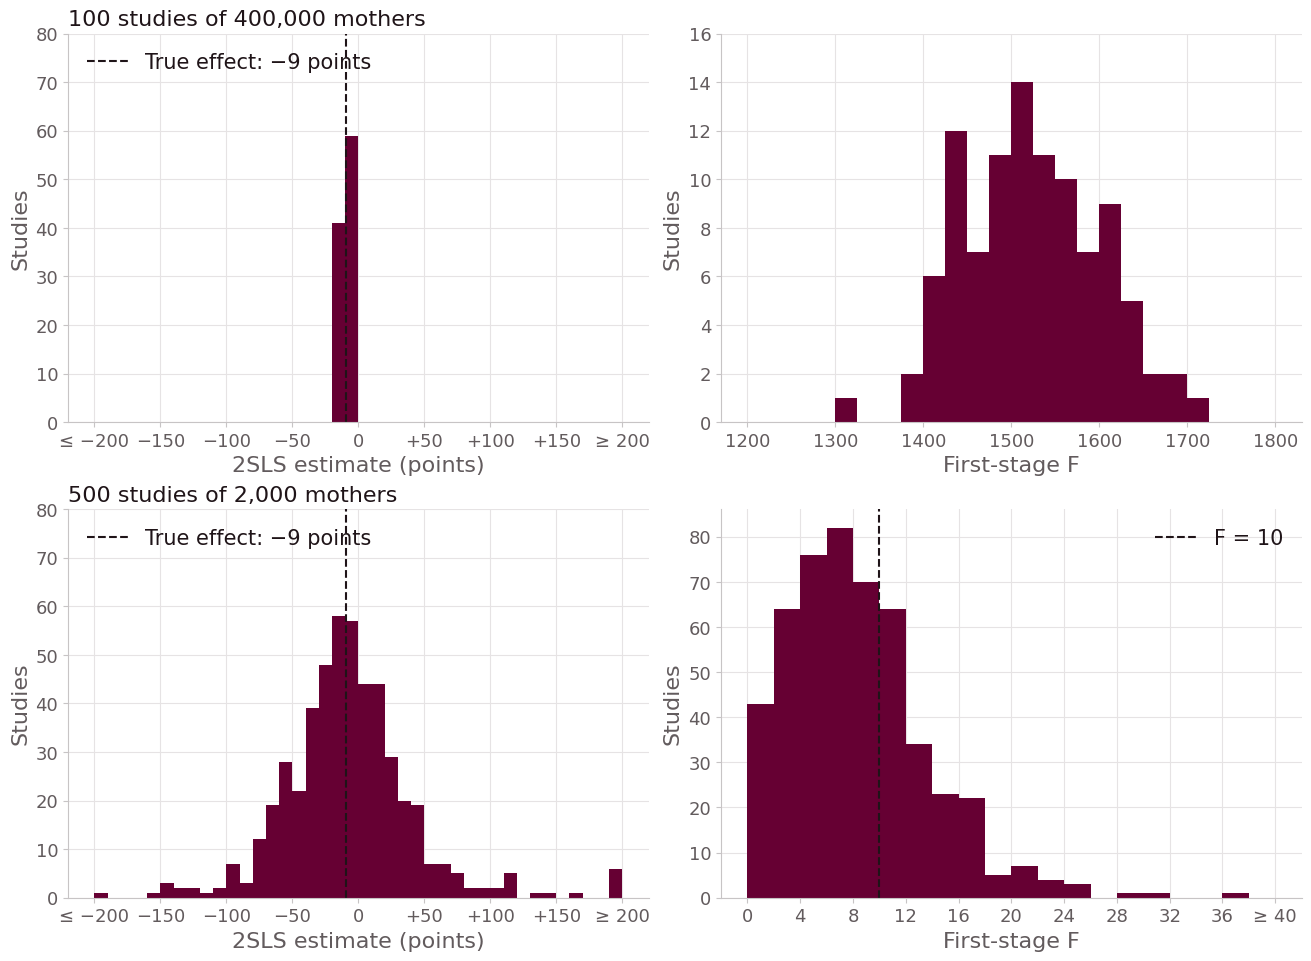

400,000 mothers: median F 1,515.2; F below 10 in 0% of studies; middle half of the estimates -11 to -7 points; beyond ±100: 0%
2,000 mothers: median F 7.5; F below 10 in 67% of studies; middle half of the estimates -34 to +15 points; beyond ±100: 6%


In [9]:
rng = np.random.default_rng(SEED + 282)
rows = []
for size, count in [(2_000, 500), (400_000, 100)]:          # big studies are slow to simulate, so fewer of them
    for study in range(count):
        data = make_mothers(size, rng)
        first_stage = robust("third_child ~ same_sex", data)
        reduced_form = robust("works ~ same_sex", data)
        estimate = reduced_form.params["same_sex"] / first_stage.params["same_sex"]
        rows.append({"Mothers": size, "F": first_stage.fvalue, "Estimate": 100 * estimate})
studies = pd.DataFrame(rows)
big = studies[studies.Mothers == studies.Mothers.max()]
small = studies[studies.Mothers == studies.Mothers.min()]

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
for ax, group in [(axes[0, 0], big), (axes[1, 0], small)]:
    ax.hist(group.Estimate.clip(-200, 200), bins=np.arange(-200, 201, 10), color="#660033")
    ax.axvline(-9, color="#1F1418", ls="--", lw=1.5, label="True effect: −9 points")
    ax.set_xticks(range(-200, 201, 50),
                  ["≤ −200", "−150", "−100", "−50", "0", "+50", "+100", "+150", "≥ 200"])
    ax.set(xlabel="2SLS estimate (points)", ylabel="Studies", ylim=(0, 80))
    ax.legend(loc="upper left")
axes[0, 0].set_title(f"{len(big)} studies of {big.Mothers.iloc[0]:,} mothers", loc="left", fontsize=16)
axes[1, 0].set_title(f"{len(small)} studies of {small.Mothers.iloc[0]:,} mothers", loc="left", fontsize=16)
axes[0, 1].hist(big.F, bins=np.arange(1200, 1801, 25), color="#660033")
axes[0, 1].set_xticks(range(1200, 1801, 100))
axes[1, 1].hist(small.F.clip(upper=40), bins=np.arange(0, 41, 2), color="#660033")
axes[1, 1].axvline(10, color="#1F1418", ls="--", lw=1.5, label="F = 10")
axes[1, 1].set_xticks(range(0, 41, 4), [str(x) for x in range(0, 40, 4)] + ["≥ 40"])
axes[1, 1].legend(loc="upper right")
for ax in axes[:, 1]:
    ax.set(xlabel="First-stage F", ylabel="Studies")
for ax in [axes[0, 0], axes[1, 0], axes[1, 1]]:
    ax.set_yticks(range(0, int(ax.get_ylim()[1]) + 1, 10))
axes[0, 1].set_yticks(range(0, 17, 2))
plt.show()

for group in [big, small]:
    low, high = group.Estimate.quantile([0.25, 0.75])
    print(f"{group.Mothers.iloc[0]:,} mothers: median F {group.F.median():,.1f}; "
          f"F below 10 in {(group.F < 10).mean():.0%} of studies; "
          f"middle half of the estimates {low:+.0f} to {high:+.0f} points; "
          f"beyond ±100: {(group.Estimate.abs() > 100).mean():.0%}")

## 4. Regression discontinuity

---

Many things in life are governed by cutoffs. In a **sharp regression discontinuity design** (RDD), $S$ switches on when a running variable $R$ reaches a cutoff $c$:

$$
S=\begin{cases}1 & \text{if } R\geq c\\ 0 & \text{if } R<c.\end{cases}
$$

People just above and just below $c$ face different rules but should otherwise be comparable. The key assumption is that

$$
\mathbb E[Y(S=1,U)\mid R=r]\quad\text{and}\quad \mathbb E[Y(S=0,U)\mid R=r]
$$

are smooth at $r=c$: outcomes don't jump at the cutoff for any reason other than $S$.

### Incumbency advantage

Does being the incumbent help a candidate in a House election?

- $Y$: the party's vote share in this election
- $S=1$ if the party's candidate is the incumbent, that is, won the last election
- $R$: the party's vote share in the last election, with cutoff $c=0.5$

In our 6,500 simulated races, each candidate has a hidden **popularity**. Each election's vote share comes from popularity plus that election's luck, squeezed between 0 and 1. Popular candidates also have more **experience**. Being the incumbent adds 6 points to this election's vote share.

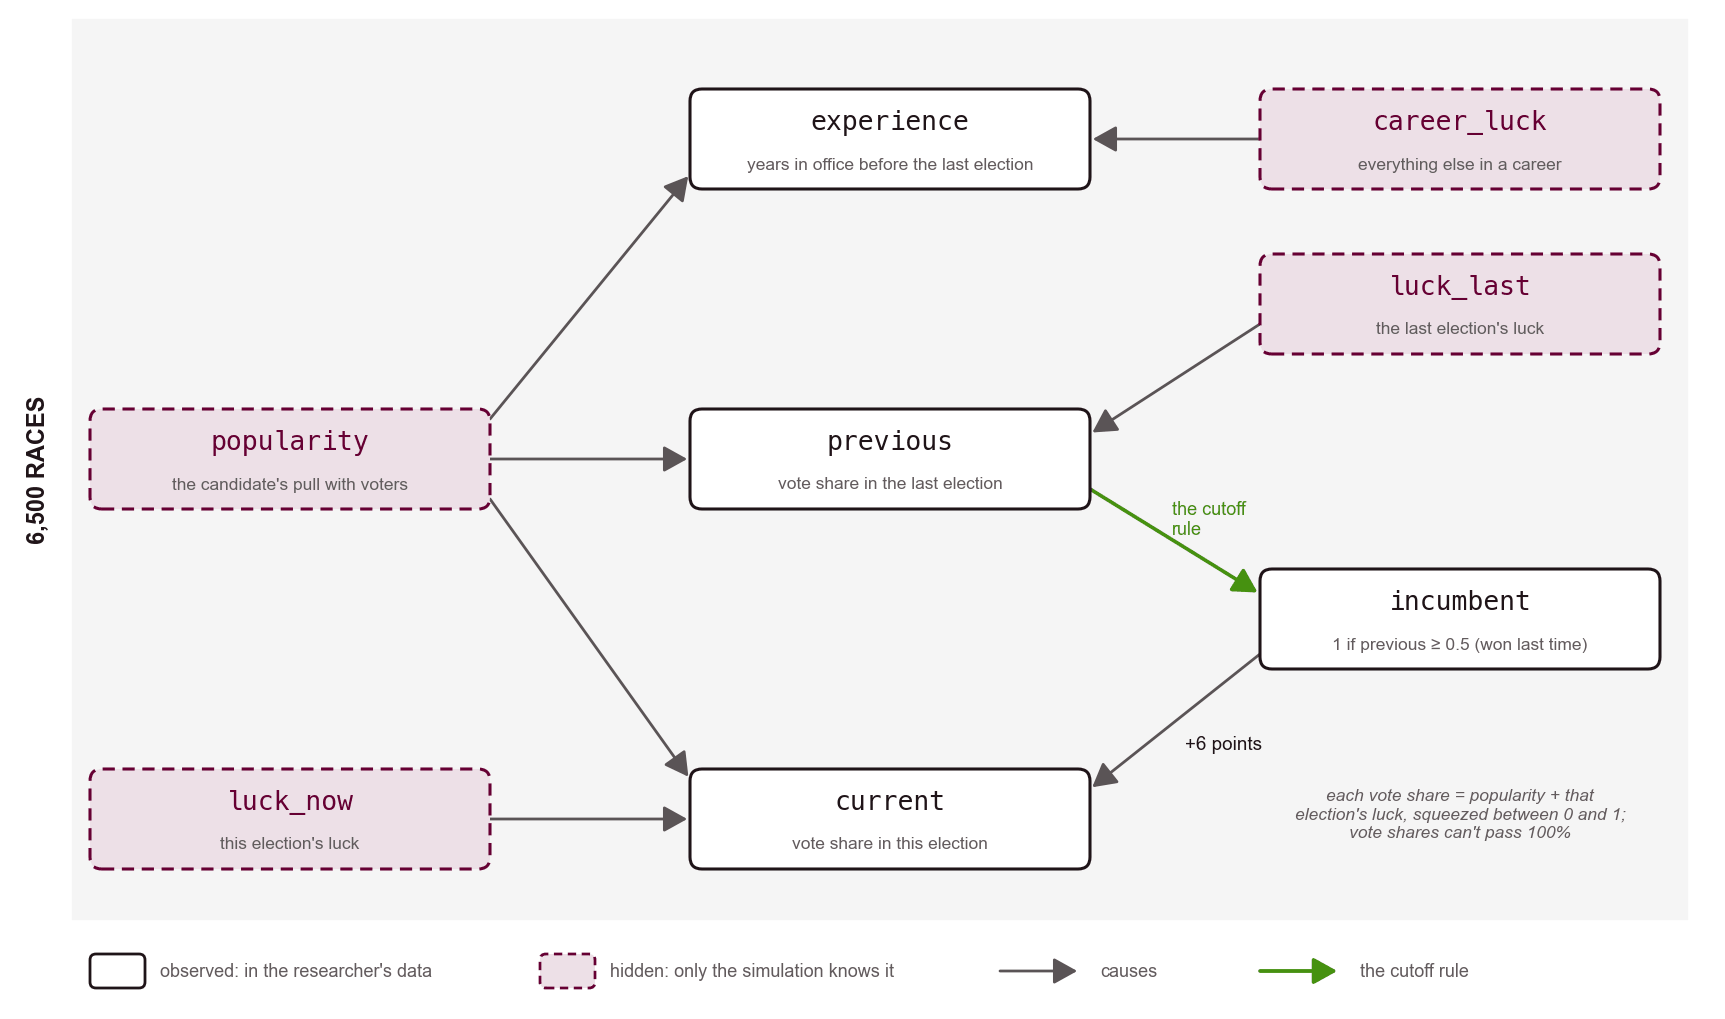

### Question 7: predict before running

1. Will incumbents' vote share this time be more or less than 6 points above non-incumbents'? Why?
2. Which races can tell us about the 6 points?

In [10]:
def make_elections(n, rng, popular_push=0.0):
    """House races: one party's vote share in the last election and in this one."""
    popularity = rng.normal(0, 1, n)                     # UNOBSERVED: the candidate's pull with voters
    career_luck = rng.normal(0, 2, n)                    # UNOBSERVED
    luck_last = rng.normal(0, 0.4, n)                    # UNOBSERVED
    luck_now = rng.normal(0, 0.3, n)                     # UNOBSERVED

    experience = np.clip(np.round(5 + 2 * popularity + career_luck), 0, None)   # years in office so far
    previous = 1 / (1 + np.exp(-(popularity + luck_last)))                       # squeezed between 0 and 1
    if popular_push:   # Section 5: popular candidates heading for a narrow loss find the money to win
        heading_for_narrow_loss = (previous >= 0.46) & (previous < 0.50) & (popularity > 0)
        pushed = heading_for_narrow_loss & (rng.uniform(0, 1, n) < popular_push)
        previous = np.where(pushed, rng.uniform(0.50, 0.51, n), previous)
    incumbent = (previous >= 0.5).astype(int)                                     # the cutoff rule
    current = np.minimum(1 / (1 + np.exp(-(popularity + luck_now))) + 0.06 * incumbent, 1)   # can't pass 100%
    return pd.DataFrame({"previous": previous, "incumbent": incumbent,
                         "experience": experience, "current": current})


elections = make_elections(6_500, np.random.default_rng(SEED + 579))
display(elections.head().style.format({"previous": "{:.3f}", "current": "{:.3f}", "experience": "{:.0f}"}))

gap = elections[elections.incumbent == 1].current.mean() - elections[elections.incumbent == 0].current.mean()
print(f"Incumbents' vote share minus non-incumbents': {100 * gap:+.1f} points")

,previous,incumbent,experience,current
0,0.458,0,4,0.559
1,0.351,0,5,0.451
2,0.674,1,9,0.546
3,0.623,1,5,0.667
4,0.385,0,7,0.527


Incumbents' vote share minus non-incumbents': +37.4 points


First, check that the rule really is sharp: winning should switch from never to always at 50%. Then look at the raw picture: races grouped by last time's vote share, 2 points at a time.

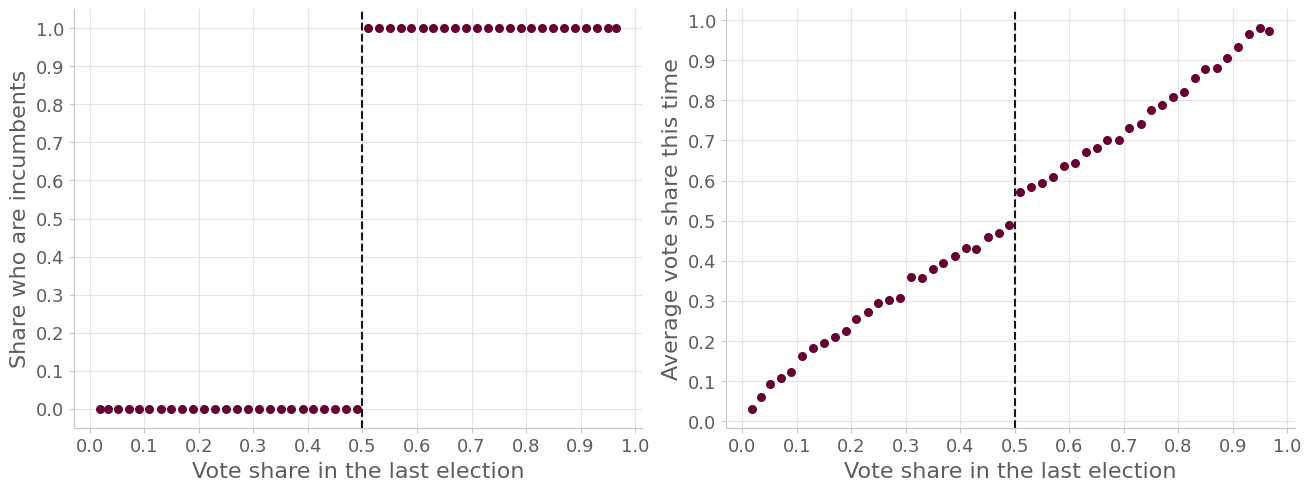

In [11]:
bins = np.arange(0, 1.0001, 0.02)
groups = elections.groupby(pd.cut(elections.previous, bins), observed=True)
binned = groups[["previous", "incumbent", "current"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(binned.previous, binned.incumbent, s=30, color="#660033")
axes[0].set(ylabel="Share who are incumbents")
axes[1].scatter(binned.previous, binned.current, s=30, color="#660033")
axes[1].set(ylabel="Average vote share this time")
for ax in axes:
    ax.axvline(0.5, color="#1F1418", ls="--", lw=1.5)
    ax.set(xlabel="Vote share in the last election")
    ax.set_xticks(np.arange(0, 1.01, 0.1))
    ax.set_yticks(np.arange(0, 1.01, 0.1))
plt.show()

### Local linear regression

Few races land exactly at 50%, so we use the races within a **bandwidth** $b$ of the cutoff, $R\in(c-b,\,c+b)$, and fit

$$
Y=\alpha_0+\alpha_1S+\alpha_2(R-c)+\alpha_3S\,(R-c).
$$

$\alpha_2$ and $\alpha_2+\alpha_3$ are the slopes below and above the cutoff. They let the vote share change with $R$, and they are descriptive, not causal. Because $R-c=0$ at the cutoff, $\alpha_1$ is the jump there: it estimates $\mathbb E[Y(S=1,U)-Y(S=0,U)\mid R=c]$, the effect for races right at 50%.

### Question 8: predict before running

We use three bandwidths: 0.01, 0.05 and 0.10.

1. The 0.05 window holds about 5 times as many races as the 0.01 window. Roughly how much smaller will its standard error be?
2. Which estimate is more believable as the effect at 50%, and why?

In [12]:
elections["margin"] = elections.previous - 0.5            # R - c
rdd = "current ~ incumbent + margin + incumbent:margin"

rows = []
for b in [0.01, 0.05, 0.10]:
    close = elections[elections.margin.abs() < b]
    fit = robust(rdd, close)
    low, high = fit.conf_int().loc["incumbent"]
    rows.append({"Bandwidth": b, "Races": len(close), "Estimate (points)": 100 * fit.params["incumbent"],
                 "Robust SE": 100 * fit.bse["incumbent"], "95% CI": f"{100 * low:+.1f} to {100 * high:+.1f}"})
display(pd.DataFrame(rows).style.format({"Bandwidth": "{:.2f}", "Estimate (points)": "{:+.1f}",
                                         "Robust SE": "{:.1f}"}).hide(axis="index"))

Bandwidth,Races,Estimate (points),Robust SE,95% CI
0.01,185,+4.9,3.4,-1.7 to +11.6
0.05,978,+5.7,1.5,+2.8 to +8.5
0.10,1924,+6.2,1.0,+4.2 to +8.2


The fit for the 0.05 bandwidth, drawn over the races grouped half a point at a time:

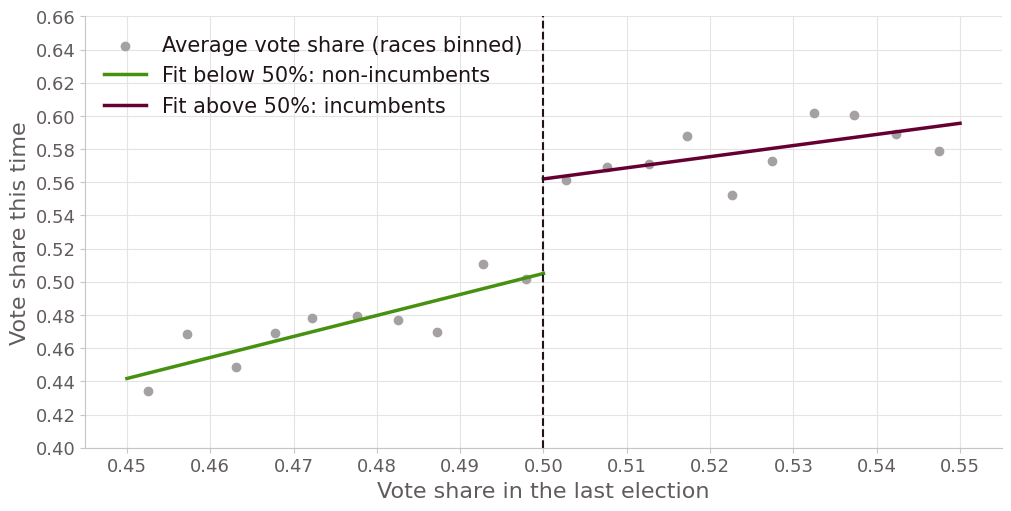

Jump at 50%: +5.7 points


In [13]:
b = 0.05
close = elections[elections.margin.abs() < b]
a = robust(rdd, close).params
groups = close.groupby(pd.cut(close.margin, np.arange(-b, b + 0.0001, 0.005)), observed=True)
binned = groups[["margin", "current"]].mean()
left, right = np.linspace(-b, 0, 50), np.linspace(0, b, 50)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(0.5 + binned.margin, binned.current, s=36, color="#A5A1A3", label="Average vote share (races binned)")
ax.plot(0.5 + left, a["Intercept"] + a["margin"] * left,
        color="#469110", lw=2.5, label="Fit below 50%: non-incumbents")
ax.plot(0.5 + right, a["Intercept"] + a["incumbent"] + (a["margin"] + a["incumbent:margin"]) * right,
        color="#660033", lw=2.5, label="Fit above 50%: incumbents")
ax.axvline(0.5, color="#1F1418", ls="--", lw=1.5)
ax.set_xticks(np.arange(0.45, 0.5501, 0.01))
ax.set_yticks(np.arange(0.40, 0.661, 0.02))
ax.set(xlabel="Vote share in the last election", ylabel="Vote share this time")
ax.legend(loc="upper left")
plt.show()
print(f"Jump at 50%: {100 * a['incumbent']:+.1f} points")

### Every bandwidth

Three bandwidths are three choices. Let's try every bandwidth from 0.01 to 0.30.

### Question 9: predict before running

1. What will happen to the confidence interval as the bandwidth grows?
2. The effect at 50% is exactly 6 points. Why might the estimate drift away from 6 at large bandwidths?

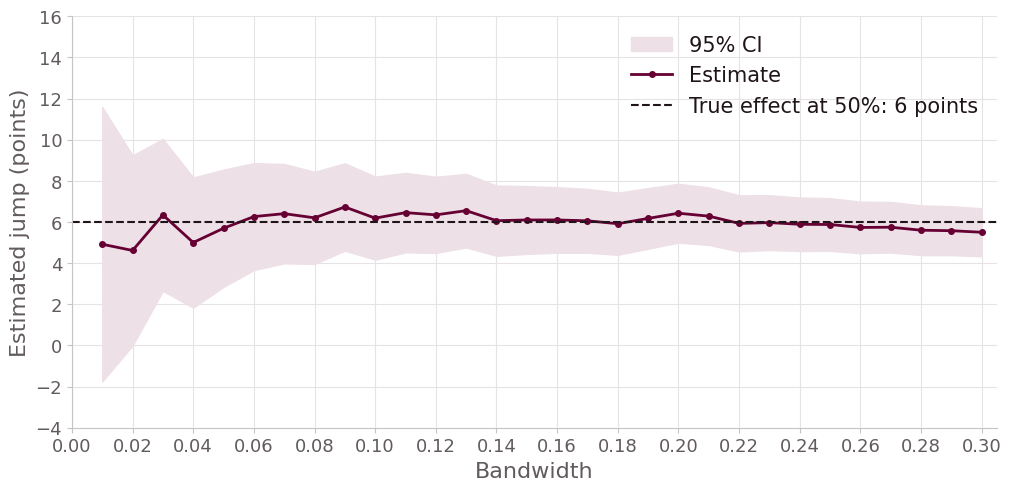

Bandwidth,Estimate,Low,High
0.01,+4.9,-1.7,+11.6
0.05,+5.7,+2.8,+8.5
0.10,+6.2,+4.2,+8.2
0.20,+6.4,+5.0,+7.9
0.30,+5.5,+4.3,+6.7


In [14]:
rows = []
for b in np.arange(0.01, 0.3001, 0.01):
    fit = robust(rdd, elections[elections.margin.abs() < b])
    low, high = fit.conf_int().loc["incumbent"]
    rows.append({"Bandwidth": b, "Estimate": 100 * fit.params["incumbent"], "Low": 100 * low, "High": 100 * high})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(sweep.Bandwidth, sweep.Low, sweep.High, color="#EDE0E7", label="95% CI")
ax.plot(sweep.Bandwidth, sweep.Estimate, "o-", color="#660033", lw=2, ms=4, label="Estimate")
ax.axhline(6, color="#1F1418", ls="--", lw=1.5, label="True effect at 50%: 6 points")
ax.set_xticks(np.arange(0, 0.3001, 0.02))
ax.set_yticks(range(-4, 17, 2))
ax.set(xlabel="Bandwidth", ylabel="Estimated jump (points)", xlim=(0, 0.305))
ax.legend(loc="upper right")
plt.show()
some = sweep.iloc[[0, 4, 9, 19, 29]]           # bandwidths 0.01, 0.05, 0.10, 0.20 and 0.30
display(some.style.format("{:.2f}", subset="Bandwidth").format("{:+.1f}", subset=["Estimate", "Low", "High"])
        .hide(axis="index"))

## 5. Checking the design

---

Two checks come next: the jump at 50% in a column that was fixed before the last election, and the number of races on each side of 50%.

### Question 10: predict before running

1. If the design works, what should the jump in `experience` at 50% be? Would that prove smoothness?
2. What should the number of races just below and just above 50% look like?

Jump in experience at 50% (bandwidth 0.05): -0.02 years (95% CI -0.57 to +0.53)
Races within a point below 50%: 95; within a point above: 90


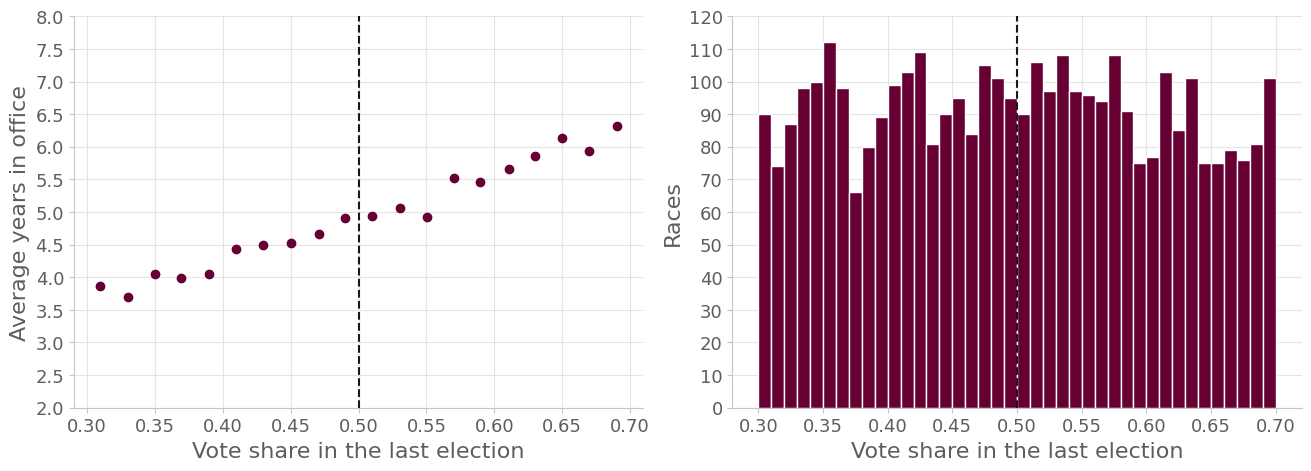

In [15]:
close = elections[elections.margin.abs() < 0.05]
fit = robust("experience ~ incumbent + margin + incumbent:margin", close)
low, high = fit.conf_int().loc["incumbent"]
print(f"Jump in experience at 50% (bandwidth 0.05): {fit.params['incumbent']:+.2f} years "
      f"(95% CI {low:+.2f} to {high:+.2f})")

just_below = ((elections.margin >= -0.01) & (elections.margin < 0)).sum()
just_above = ((elections.margin >= 0) & (elections.margin < 0.01)).sum()
print(f"Races within a point below 50%: {just_below}; within a point above: {just_above}")

near = elections[elections.previous.between(0.3, 0.7)]
groups = near.groupby(pd.cut(near.previous, np.arange(0.3, 0.7001, 0.02)), observed=True)
binned = groups[["previous", "experience"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(binned.previous, binned.experience, s=36, color="#660033")
axes[0].set(ylabel="Average years in office")
axes[0].set_yticks(np.arange(2, 8.1, 0.5))
axes[1].hist(near.previous, bins=np.arange(0.3, 0.7001, 0.01), color="#660033", edgecolor="white")
axes[1].set(ylabel="Races")
axes[1].set_yticks(range(0, 121, 10))
for ax in axes:
    ax.axvline(0.5, color="#1F1418", ls="--", lw=1.5)
    ax.set(xlabel="Vote share in the last election")
    ax.set_xticks(np.arange(0.3, 0.7001, 0.05))
plt.show()

### When candidates can choose their side

Now suppose popular candidates who are heading for a narrow loss, with 46% to 50% of the vote, can find just enough money to win: 4 in 10 of them end up just above 50%. Everything else about the races, including their luck, stays the same.

### Question 11: predict before running

1. What can we check to catch this?
2. Will the RDD estimate be too high or too low? Why?

Races,Just below 50%,Just above 50%,Jump in experience (years),"Estimate, b = 0.01 (points)","Estimate, b = 0.05 (points)"
Before,95,90,-0.02,+4.9,+5.7
Popular candidates can buy a narrow win,74,151,+0.38,+10.8,+10.3


The true effect at 50% is still 6 points.


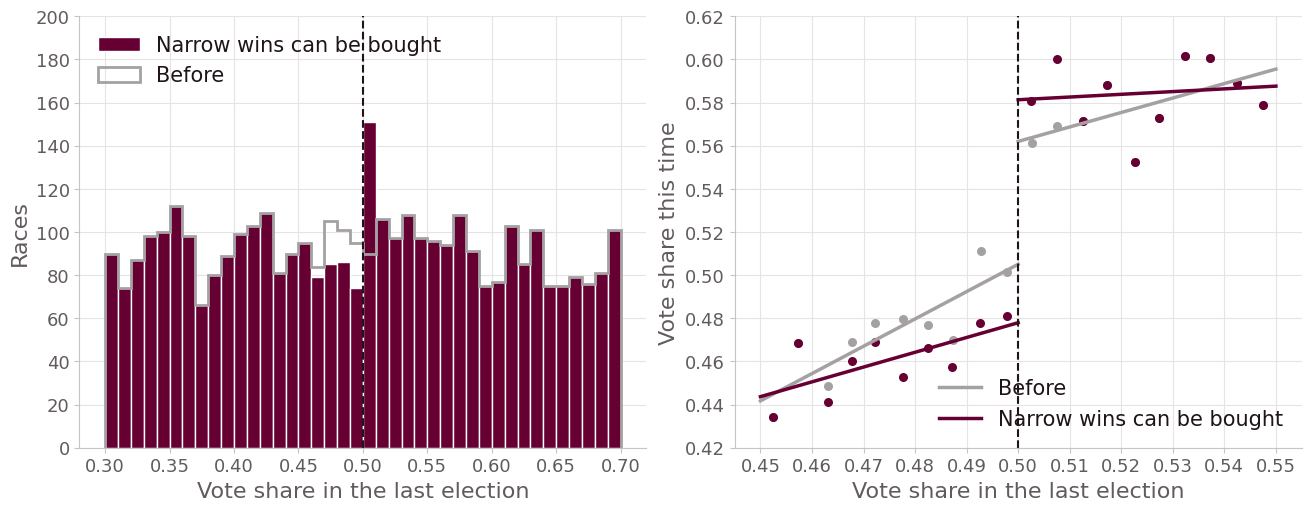

In [16]:
pushed = make_elections(6_500, np.random.default_rng(SEED + 579), popular_push=0.4)
pushed["margin"] = pushed.previous - 0.5

rows = []
for label, data in [("Before", elections), ("Popular candidates can buy a narrow win", pushed)]:
    narrow, wide = data[data.margin.abs() < 0.01], data[data.margin.abs() < 0.05]
    rows.append({"Races": label,
                 "Just below 50%": ((data.margin >= -0.01) & (data.margin < 0)).sum(),
                 "Just above 50%": ((data.margin >= 0) & (data.margin < 0.01)).sum(),
                 "Jump in experience (years)": robust("experience ~ incumbent + margin + incumbent:margin",
                                                      wide).params["incumbent"],
                 "Estimate, b = 0.01 (points)": 100 * robust(rdd, narrow).params["incumbent"],
                 "Estimate, b = 0.05 (points)": 100 * robust(rdd, wide).params["incumbent"]})
display(pd.DataFrame(rows).style.format("{:+.2f}", subset="Jump in experience (years)")
        .format("{:+.1f}", subset=["Estimate, b = 0.01 (points)", "Estimate, b = 0.05 (points)"]).hide(axis="index"))
print("The true effect at 50% is still 6 points.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.arange(0.3, 0.7001, 0.01)
axes[0].hist(pushed.previous, bins=bins, color="#660033", edgecolor="white", label="Narrow wins can be bought")
axes[0].hist(elections.previous, bins=bins, histtype="step", color="#A5A1A3", lw=2, label="Before")
axes[0].set_xticks(np.arange(0.3, 0.7001, 0.05))
axes[0].set_yticks(range(0, 201, 20))
axes[0].set(xlabel="Vote share in the last election", ylabel="Races", ylim=(0, 200))

b = 0.05
left, right = np.linspace(-b, 0, 50), np.linspace(0, b, 50)
for data, color, label in [(elections, "#A5A1A3", "Before"), (pushed, "#660033", "Narrow wins can be bought")]:
    close = data[data.margin.abs() < b]
    a = robust(rdd, close).params
    groups = close.groupby(pd.cut(close.margin, np.arange(-b, b + 0.0001, 0.005)), observed=True)
    binned = groups[["margin", "current"]].mean()
    axes[1].scatter(0.5 + binned.margin, binned.current, s=30, color=color)
    axes[1].plot(0.5 + left, a["Intercept"] + a["margin"] * left, color=color, lw=2.5, label=label)
    axes[1].plot(0.5 + right, a["Intercept"] + a["incumbent"] + (a["margin"] + a["incumbent:margin"]) * right,
                 color=color, lw=2.5)
axes[1].set_xticks(np.arange(0.45, 0.5501, 0.01))
axes[1].set_yticks(np.arange(0.42, 0.621, 0.02))
axes[1].set(xlabel="Vote share in the last election", ylabel="Vote share this time")
axes[0].legend(loc="upper left")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.axvline(0.5, color="#1F1418", ls="--", lw=1.5)
plt.show()